# ANA500 Micro-Project 4: Machine Learning Project 2 of 2
**Pius Olaniyan**<br>
**Dataset:** World Happiness Report 2024 (yearly panel, Gallup World Poll)

In Micro-Project 3 I used linear regression and SVM regression to predict a country's life satisfaction from six
factors measured in the same year. The RBF SVM won with an average error of about 0.43 points. That model only looked
at one year at a time, though. It had no idea where a country was coming from.

For this project I wanted to use deep learning, and recurrent neural networks in particular, because they're built
for data that comes in order over time. My data is a panel: the same countries measured year after year. So the
question changes a bit. Instead of "what's this country's score right now," I'm asking "given the last three years,
what will this country's score be next year?"

## Problem statement and hypothesis

**Problem statement.** Life satisfaction moves slowly in most countries, but sometimes it drops or jumps fast (think
Lebanon's economic collapse or Afghanistan after 2021). I want to see if a recurrent neural network that reads a
country's last three years of data can forecast next year's score for countries it has never seen, and whether it
does better than simpler approaches.

**Hypothesis.** I have two parts:

1. An RNN that sees three years of history will beat my best model from Micro-Project 3 (the RBF SVM, MAE 0.43),
   because it knows the country's recent scores and trends, not just one year's snapshot.
2. The RNN will also beat the simplest possible forecast, which is just "next year will be the same as this year."
   I expect a model that can see trends in income, corruption and so on to catch changes that the naive guess misses.

## Setup
Same libraries as Micro-Project 3, plus TensorFlow/Keras for the neural networks. I set random seeds so the results
come out the same every time I run it. Neural networks start from random weights, so without a seed every run gives
slightly different numbers.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # hide TensorFlow's startup messages
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"         # turn off a CPU optimization notice (and tiny rounding differences)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR")                # hide retracing warnings during training loops

SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 1. Acquire

Same file as my first three micro-projects: the "World Happiness Report 2024 (Yearly Updated)" CSV from Kaggle. Each
row is one country in one survey year, from 2005 to 2023. I still have to open it with Latin-1 encoding because
UTF-8 breaks on "Türkiye".

In [2]:
raw = pd.read_csv("World-happiness-report-updated_2024.csv", encoding="latin-1")
print("Rows, columns:", raw.shape)
print("Countries:", raw["Country name"].nunique(), "| Years:", raw["year"].min(), "to", raw["year"].max())
raw.head()

Rows, columns: (2363, 11)
Countries: 165 | Years: 2005 to 2023


,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.724,7.350,0.451,50.5,0.718,0.164,0.882,0.414,0.258
1,Afghanistan,2009,4.402,7.509,0.552,50.8,0.679,0.187,0.850,0.481,0.237
2,Afghanistan,2010,4.758,7.614,0.539,51.1,0.600,0.118,0.707,0.517,0.275
3,Afghanistan,2011,3.832,7.581,0.521,51.4,0.496,0.160,0.731,0.480,0.267
4,Afghanistan,2012,3.783,7.661,0.521,51.7,0.531,0.234,0.776,0.614,0.268


## Step 2. Prepare

### 2.1 Same cleaning as Micro-Projects 1 to 3
I kept every cleaning choice from before so all four projects line up:

1. Shorter column names.
2. Haiti's healthy life expectancy for 2006 to 2014 is a made up straight line, so I set it to missing.
3. Gaps get filled inside each country first (interpolate, then fill forward or back). Only whatever is still
   missing after that gets the year's median.

In [3]:
# 1. Shorter column names
df = raw.rename(columns={
    "Country name": "country", "Life Ladder": "ladder", "Log GDP per capita": "log_gdp",
    "Social support": "social_support", "Healthy life expectancy at birth": "healthy_life_exp",
    "Freedom to make life choices": "freedom", "Generosity": "generosity",
    "Perceptions of corruption": "corruption", "Positive affect": "positive_affect",
    "Negative affect": "negative_affect"})

# 2. Haiti's pre 2015 life expectancy values aren't real measurements
bad_haiti = (df["country"] == "Haiti") & (df["year"] < 2015)
df.loc[bad_haiti, "healthy_life_exp"] = np.nan

all_factors = ["log_gdp", "social_support", "healthy_life_exp", "freedom",
               "generosity", "corruption", "positive_affect", "negative_affect"]
df = df.sort_values(["country", "year"]).reset_index(drop=True)

# Remember which rows had no measured income BEFORE filling anything (used in 2.2)
income_not_measured = df["log_gdp"].isna()
print("Missing values before filling:", df[all_factors].isna().sum().sum())

# 3a. Fill inside each country
for col in all_factors:
    df[col] = (df.groupby("country")[col]
                 .transform(lambda s: s.interpolate(limit_area="inside").ffill().bfill()))
# 3b. Whatever is still missing gets that year's median
for col in all_factors:
    df[col] = df[col].fillna(df.groupby("year")[col].transform("median"))
print("Missing values after filling:", df[all_factors].isna().sum().sum())

Missing values before filling: 393


Missing values after filling: 0


### 2.2 Drop rows where income was never measured
Same as Micro-Project 3. A few countries (Venezuela, Palestine, Taiwan, Yemen and a couple of others) had old income
values carried forward, so I drop every row where income wasn't actually reported.

In [4]:
print("Rows dropped:", income_not_measured.sum())
data = df[~income_not_measured].reset_index(drop=True)
print("Rows left:", len(data), "| Countries left:", data["country"].nunique())

Rows dropped: 28
Rows left: 2335 | Countries left: 162


### 2.3 Turn the panel into 3 year sequences
This is the big new prep step. An RNN doesn't take one row, it takes a sequence. So for every country and every year
*t*, I build a little 3 x 7 table:

* 3 rows, one each for years *t-3*, *t-2* and *t-1*
* 7 columns: the six factors from MP3 plus that year's life satisfaction score

The target is the life satisfaction score in year *t*. So the model only gets to look at the past, which is what a
real forecast would do.

Two decisions I made here:

* **The three years have to be back to back.** Some countries skip survey years. If I let a sequence jump from 2008
  to 2012, the RNN would think those were neighboring years. So I only keep windows where all three years exist.
* **Why three years?** More years would give the RNN more history, but every extra year I require throws away more
  windows, especially for countries that joined the survey late. Three felt like a fair middle ground. I talk about
  this again in the limitations.

I still leave out positive and negative affect, same reason as MP3. They're other mood questions from the same survey.

In [5]:
features = ["log_gdp", "social_support", "healthy_life_exp", "freedom", "generosity", "corruption"]
seq_cols = features + ["ladder"]        # what the RNN sees for each past year
WINDOW = 3

X_seq, y_all, country_all, year_all, last_score, current_factors = [], [], [], [], [], []
for country, g in data.groupby("country"):
    g = g.set_index("year")
    for t in g.index:
        past_years = [t - k for k in range(WINDOW, 0, -1)]      # e.g. [2017, 2018, 2019] for t = 2020
        if all(yr in g.index for yr in past_years):             # only keep back to back years
            X_seq.append(g.loc[past_years, seq_cols].values)
            y_all.append(g.loc[t, "ladder"])
            country_all.append(country)
            year_all.append(t)
            last_score.append(g.loc[t - 1, "ladder"])           # needed for the naive forecast
            current_factors.append(g.loc[t, features].values)   # needed to rerun the MP3 model

X_seq = np.array(X_seq, dtype=float)
y_all = np.array(y_all)
country_all = np.array(country_all)
year_all = np.array(year_all)
last_score = np.array(last_score)
current_factors = np.array(current_factors, dtype=float)

print("Sequence array shape (windows, years, columns):", X_seq.shape)
print("Countries with at least one full window:", len(set(country_all)))
print("Target years covered:", year_all.min(), "to", year_all.max())

Sequence array shape (windows, years, columns): (1601, 3, 7)
Countries with at least one full window: 148
Target years covered: 2009 to 2023


Here's what one window looks like, so it's clear what the RNN is actually reading. This is Finland, predicting 2020:

In [6]:
i = np.where((country_all == "Finland") & (year_all == 2020))[0][0]
example = pd.DataFrame(X_seq[i], columns=seq_cols, index=[2017, 2018, 2019]).round(3)
display(example)
print("Target (Finland 2020 life satisfaction):", round(y_all[i], 3))

,log_gdp,social_support,healthy_life_exp,freedom,generosity,corruption,ladder
2017,10.770,0.964,70.850,0.962,-0.008,0.192,7.788
2018,10.780,0.962,70.925,0.938,-0.133,0.199,7.858
2019,10.791,0.937,71.000,0.948,-0.058,0.195,7.780


Target (Finland 2020 life satisfaction): 7.889


### 2.4 Split by country, using the same test countries as MP3
Same rule as last time: a country is either all in training or all in testing, never both. Otherwise Finland 2019
could be in training and Finland 2020 in testing, and the model would just remember Finland.

I used the exact same split (`GroupShuffleSplit`, 20% test, seed 42) as Micro-Project 3 so the two projects are tested
on the same countries. Two of those 33 test countries don't have three back to back survey years anywhere, so they
drop out and I end up with 31.

I also hold out 15% of the training countries as a **validation set**. The neural networks use it to decide when to
stop training (early stopping), so the test countries stay completely untouched until the very end.

In [7]:
# Recreate MP3's exact country split
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
_, mp3_test_idx = next(gss.split(data, data["ladder"], data["country"]))
test_countries = set(data["country"].iloc[mp3_test_idx])

is_test = np.isin(country_all, list(test_countries))
X_train_raw, X_test_raw = X_seq[~is_test], X_seq[is_test]
y_train, y_test = y_all[~is_test], y_all[is_test]
last_train, last_test = last_score[~is_test], last_score[is_test]
c_train, c_test = country_all[~is_test], country_all[is_test]

# Validation countries come only from the training side
train_country_list = np.array(sorted(set(c_train)))
rng = np.random.RandomState(SEED)
val_countries = set(rng.choice(train_country_list, int(0.15 * len(train_country_list)), replace=False))
is_val = np.isin(c_train, list(val_countries))

print(f"Training:   {(~is_val).sum()} windows from {len(set(c_train)) - len(val_countries)} countries")
print(f"Validation: {is_val.sum()} windows from {len(val_countries)} countries")
print(f"Testing:    {len(y_test)} windows from {len(set(c_test))} countries")
print("Overlap between train and test countries:", len(set(c_train) & set(c_test)))

Training:   1064 windows from 100 countries
Validation: 190 windows from 17 countries
Testing:    347 windows from 31 countries
Overlap between train and test countries: 0


### 2.5 Scale the inputs
Neural networks train much better when every input is on a similar scale. Log GDP is around 9 to 11, while
corruption is between 0 and 1. I fit a `StandardScaler` on the training windows only (so nothing about the test
countries leaks in), then apply it to everything. I have to flatten the 3D array to 2D to scale it and then reshape it
back.

In [8]:
n_cols = X_seq.shape[2]
scaler = StandardScaler().fit(X_train_raw.reshape(-1, n_cols))

def scale(arr):
    # flatten to (windows * years, columns), scale, then put back to (windows, years, columns)
    return scaler.transform(arr.reshape(-1, n_cols)).reshape(arr.shape)

X_train, X_test = scale(X_train_raw), scale(X_test_raw)
print("Scaled training data mean:", X_train.mean().round(3), "| std:", X_train.std().round(3))

Scaled training data mean: 0.0 | std: 1.0


## Step 3. Analyze

### 3.1 Baselines first
Before training any neural networks, I need something to compare them to. Otherwise I can't tell if the RNN is
actually good or just looks good. I set up three baselines:

| Baseline | What it does | Why it's here |
|---|---|---|
| Naive forecast | Next year = this year | Simplest possible forecast. Anything useful has to beat it. |
| MP3 RBF SVM | My best model from last time, using only year *t*'s six factors | Tests hypothesis part 1 |
| Linear on window | Linear regression on all 21 numbers in the 3 year window | A non deep learning model that sees the same history as the RNN |

One note on the MP3 SVM: it actually gets to see the *current* year's factors, which the RNN doesn't. So if anything
it has a small information advantage.

In [9]:
results = {}
predictions = {}

def score(name, pred):
    results[name] = {"MAE": mean_absolute_error(y_test, pred),
                     "RMSE": mean_squared_error(y_test, pred) ** 0.5,
                     "R2": r2_score(y_test, pred)}
    predictions[name] = pred
    r = results[name]
    print(f"{name:28s} MAE {r['MAE']:.3f}   RMSE {r['RMSE']:.3f}   R2 {r['R2']:.3f}")

# Naive: same as last year
score("Naive (same as last year)", last_test)

# MP3's best model, with the settings the grid search picked last time (C=1, gamma='scale')
svm_mp3 = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=1, gamma="scale", epsilon=0.1))
svm_mp3.fit(current_factors[~is_test], y_train)
score("MP3 RBF SVM (one year)", svm_mp3.predict(current_factors[is_test]))

# Linear regression on the flattened 3 x 7 window
lin_window = make_pipeline(StandardScaler(), LinearRegression())
lin_window.fit(X_train_raw.reshape(len(X_train_raw), -1), y_train)
score("Linear on 3 yr window", lin_window.predict(X_test_raw.reshape(len(X_test_raw), -1)))

Naive (same as last year)    MAE 0.219   RMSE 0.317   R2 0.913
MP3 RBF SVM (one year)       MAE 0.406   RMSE 0.538   R2 0.750
Linear on 3 yr window        MAE 0.204   RMSE 0.286   R2 0.929


Right away, two things jump out:

* Just knowing last year's score is huge. The naive forecast has an MAE around 0.22, about half the error of my MP3
  model. Happiness is sticky from year to year.
* So hypothesis part 1 is basically going to pass no matter what, because any model that sees last year's score has a
  massive head start on the MP3 model. The real test is part 2: can the RNN beat the naive forecast?

### 3.2 Training helper
Every neural network goes through the same steps, so I wrote one function for it:

* **Adam optimizer** with learning rate 0.001 and **mean squared error** loss.
* **Early stopping**: training stops when the validation loss hasn't improved in 25 epochs, and the weights roll back
  to the best epoch. This is my main protection against overfitting.
* **Three seeds per model**: I train each network three times with different random starting weights and average the
  predictions. With only about 1,000 training windows, a single run can be noticeably lucky or unlucky.
* **target="level" or "change"**: I explain this one in 3.4.

In [10]:
def train_network(build_fn, target="level", seeds=(1, 2, 3), epochs=300, keep_history=False):
    # Train the same architecture with several seeds and average the test predictions.
    # target="level"  -> the network predicts next year's score directly
    # target="change" -> the network predicts the change from last year, then I add last year's score back
    y_fit = y_train if target == "level" else y_train - last_train
    preds, histories = [], []
    for s in seeds:
        keras.utils.set_random_seed(s)
        model = build_fn()
        model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
        hist = model.fit(X_train[~is_val], y_fit[~is_val],
                         validation_data=(X_train[is_val], y_fit[is_val]),
                         epochs=epochs, batch_size=32, verbose=0,
                         callbacks=[keras.callbacks.EarlyStopping(patience=25, restore_best_weights=True)])
        p = model.predict(X_test, verbose=0).ravel()
        if target == "change":
            p = p + last_test
        preds.append(p)
        histories.append(hist.history)
    return (np.mean(preds, axis=0), histories, model) if keep_history else np.mean(preds, axis=0)

input_shape = (WINDOW, n_cols)    # 3 years x 7 columns

### 3.3 Four network types, predicting the score directly
I tried four architectures, all kept small on purpose since my dataset is small:

* **Dense network (MLP).** Flattens the 3 x 7 window into 21 numbers. It has no idea the rows are in time order. This
  is the "deep learning but not recurrent" comparison.
* **SimpleRNN.** Reads the three years one at a time and carries a hidden state forward. The most basic recurrent
  layer.
* **LSTM.** A recurrent layer with gates that decide what to remember and what to forget. Built for longer sequences.
* **GRU.** A lighter version of the LSTM with fewer gates and fewer parameters.

Each recurrent model has 32 units feeding into one output neuron.

In [11]:
def build_mlp():
    return keras.Sequential([layers.Input(input_shape), layers.Flatten(),
                             layers.Dense(32, activation="relu"), layers.Dense(16, activation="relu"),
                             layers.Dense(1)])
def build_rnn():
    return keras.Sequential([layers.Input(input_shape), layers.SimpleRNN(32), layers.Dense(1)])
def build_lstm():
    return keras.Sequential([layers.Input(input_shape), layers.LSTM(32), layers.Dense(1)])
def build_gru():
    return keras.Sequential([layers.Input(input_shape), layers.GRU(32), layers.Dense(1)])

builders = {"Dense NN": build_mlp, "SimpleRNN": build_rnn, "LSTM": build_lstm, "GRU": build_gru}

for name, fn in builders.items():
    print(f"{name}: {fn().count_params():,} trainable parameters")
print()
for name, fn in builders.items():
    score(f"{name} (level)", train_network(fn, target="level"))

Dense NN: 1,249 trainable parameters
SimpleRNN: 1,313 trainable parameters


LSTM: 5,153 trainable parameters


GRU: 3,969 trainable parameters



Dense NN (level)             MAE 0.292   RMSE 0.400   R2 0.862


SimpleRNN (level)            MAE 0.234   RMSE 0.329   R2 0.907


LSTM (level)                 MAE 0.243   RMSE 0.322   R2 0.911


GRU (level)                  MAE 0.238   RMSE 0.315   R2 0.914


This was not what I expected. All four networks are **worse than the naive forecast** when they predict the score
directly. The dense network is the worst. The recurrent ones are closer, but still behind "same as last year."

My guess at why: the network has to rebuild the whole score from scratch (something like 5.8) using scaled inputs,
and small mistakes in that rebuild add up to bigger errors than the tiny year to year changes. The naive forecast gets
the level for free.

### 3.4 Second try: predict the change instead
Since the naive forecast is so strong, I flipped the problem around. Instead of asking the network for next year's
score, I ask it for **how much the score will change** from last year. Then I add last year's score back on.

This way the network starts from the naive forecast and only has to learn the adjustment. If it learns nothing at
all, it should land right around the naive score instead of below it. I gave the linear window model the same
treatment so the comparison stays fair.

In [12]:
lin_change = make_pipeline(StandardScaler(), LinearRegression())
lin_change.fit(X_train_raw.reshape(len(X_train_raw), -1), y_train - last_train)
score("Linear on window (change)",
      lin_change.predict(X_test_raw.reshape(len(X_test_raw), -1)) + last_test)

for name, fn in builders.items():
    score(f"{name} (change)", train_network(fn, target="change"))

Linear on window (change)    MAE 0.204   RMSE 0.286   R2 0.929


Dense NN (change)            MAE 0.218   RMSE 0.306   R2 0.919


SimpleRNN (change)           MAE 0.209   RMSE 0.293   R2 0.926


LSTM (change)                MAE 0.213   RMSE 0.300   R2 0.922


GRU (change)                 MAE 0.208   RMSE 0.296   R2 0.924


That fixed it. Every network improved once it was predicting change, and the recurrent ones now edge out the naive
forecast. The gap is small though, around 0.01 points. I'll check in Step 4 whether that holds up.

The linear model came out exactly the same both ways. That makes sense once I thought about it: last year's score is
already one of its 21 inputs, so a linear model can just give it a weight of 1 on its own. Neural networks don't find
that shortcut as easily, which is why the change version helped them so much.

### 3.5 Tuning the GRU
GRU and SimpleRNN came out about even, so I picked the GRU to tune since it's the more standard choice for
forecasting. I tried three sizes (16, 32 and 64 units) plus a version with dropout. I chose using the
**validation countries only**, not the test set, so the test score stays honest.

In [13]:
def make_gru(units, dropout=0.0):
    def fn():
        return keras.Sequential([layers.Input(input_shape),
                                 layers.GRU(units, dropout=dropout), layers.Dense(1)])
    return fn

tuning = []
for units, drop in [(16, 0.0), (32, 0.0), (64, 0.0), (32, 0.2)]:
    val_maes = []
    for s in (1, 2, 3):
        keras.utils.set_random_seed(s)
        m = make_gru(units, drop)()
        m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
        yc = y_train - last_train
        m.fit(X_train[~is_val], yc[~is_val], validation_data=(X_train[is_val], yc[is_val]),
              epochs=300, batch_size=32, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=25, restore_best_weights=True)])
        val_pred = m.predict(X_train[is_val], verbose=0).ravel() + last_train[is_val]
        val_maes.append(mean_absolute_error(y_train[is_val], val_pred))
    tuning.append({"units": units, "dropout": drop, "val_MAE": np.mean(val_maes)})

tuning = pd.DataFrame(tuning).sort_values("val_MAE")
display(tuning.round(4))
best = tuning.iloc[0]
print(f"Best on validation: {int(best.units)} units, dropout {best.dropout}")

,units,dropout,val_MAE
1,32,0.0,0.2717
3,32,0.2,0.2723
0,16,0.0,0.2727
2,64,0.0,0.2743


Best on validation: 32 units, dropout 0.0


All four settings land within about 0.003 of each other on validation, so the network size barely matters here. The
winner is 32 units with no dropout, which is the same GRU I already ran in 3.4, so its test score below matches that
one exactly. I'm retraining it here mainly to keep the training history for the plot.

In [14]:
best_pred, best_hist, best_model = train_network(make_gru(int(best.units), best.dropout),
                                                 target="change", keep_history=True)
score("GRU tuned (change)", best_pred)
best_model.summary()

GRU tuned (change)           MAE 0.208   RMSE 0.296   R2 0.924


Model: "sequential_42"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_21 (GRU)                    │ (None, 32)             │         3,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,909 (46.52 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,940 (31.02 KB)

Here's the training curve for one of the tuned GRU runs. Both losses drop fast and then flatten out. Validation loss
stops improving early, which is where early stopping kicks in. The fact that validation loss doesn't climb back up
tells me early stopping did its job and the model isn't badly overfitting.

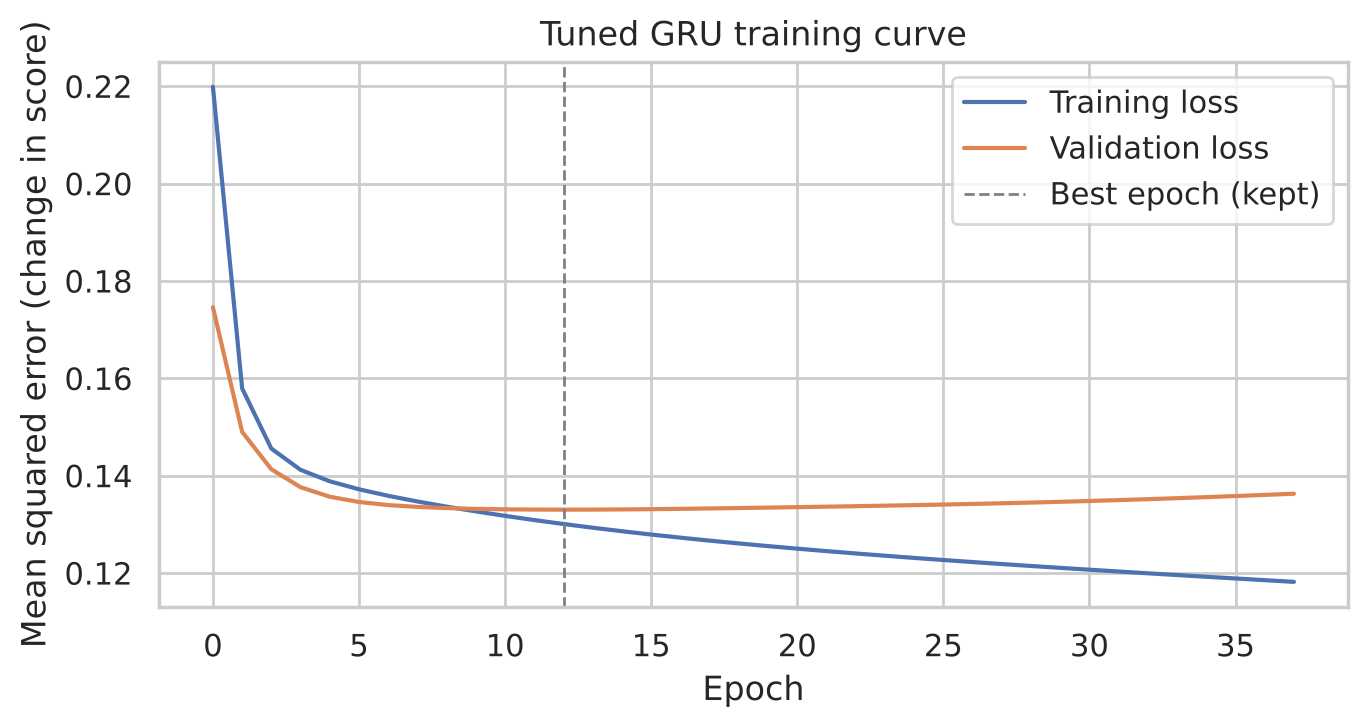

In [15]:
h = best_hist[0]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(h["loss"], label="Training loss")
ax.plot(h["val_loss"], label="Validation loss")
ax.axvline(int(np.argmin(h["val_loss"])), color="gray", ls="--", lw=1, label="Best epoch (kept)")
ax.set_xlabel("Epoch"); ax.set_ylabel("Mean squared error (change in score)")
ax.set_title("Tuned GRU training curve")
ax.legend()
plt.tight_layout(); plt.savefig("fig_training_curve.png", dpi=160); plt.show()

## Step 4. Report

### 4.1 All the results in one place

In [16]:
# The tuned GRU is the same model as "GRU (change)", and the linear model gave identical results both ways,
# so I drop those duplicate rows to keep the table readable
table = (pd.DataFrame(results).T
           .drop(index=["GRU (change)", "Linear on window (change)"])
           .sort_values("MAE"))
display(table.round(3))
table.round(4).to_csv("results_table.csv")

,MAE,RMSE,R2
Linear on 3 yr window,0.204,0.286,0.929
GRU tuned (change),0.208,0.296,0.924
SimpleRNN (change),0.209,0.293,0.926
LSTM (change),0.213,0.300,0.922
Dense NN (change),0.218,0.306,0.919
Naive (same as last year),0.219,0.317,0.913
SimpleRNN (level),0.234,0.329,0.907
GRU (level),0.238,0.315,0.914
LSTM (level),0.243,0.322,0.911
Dense NN (level),0.292,0.400,0.862


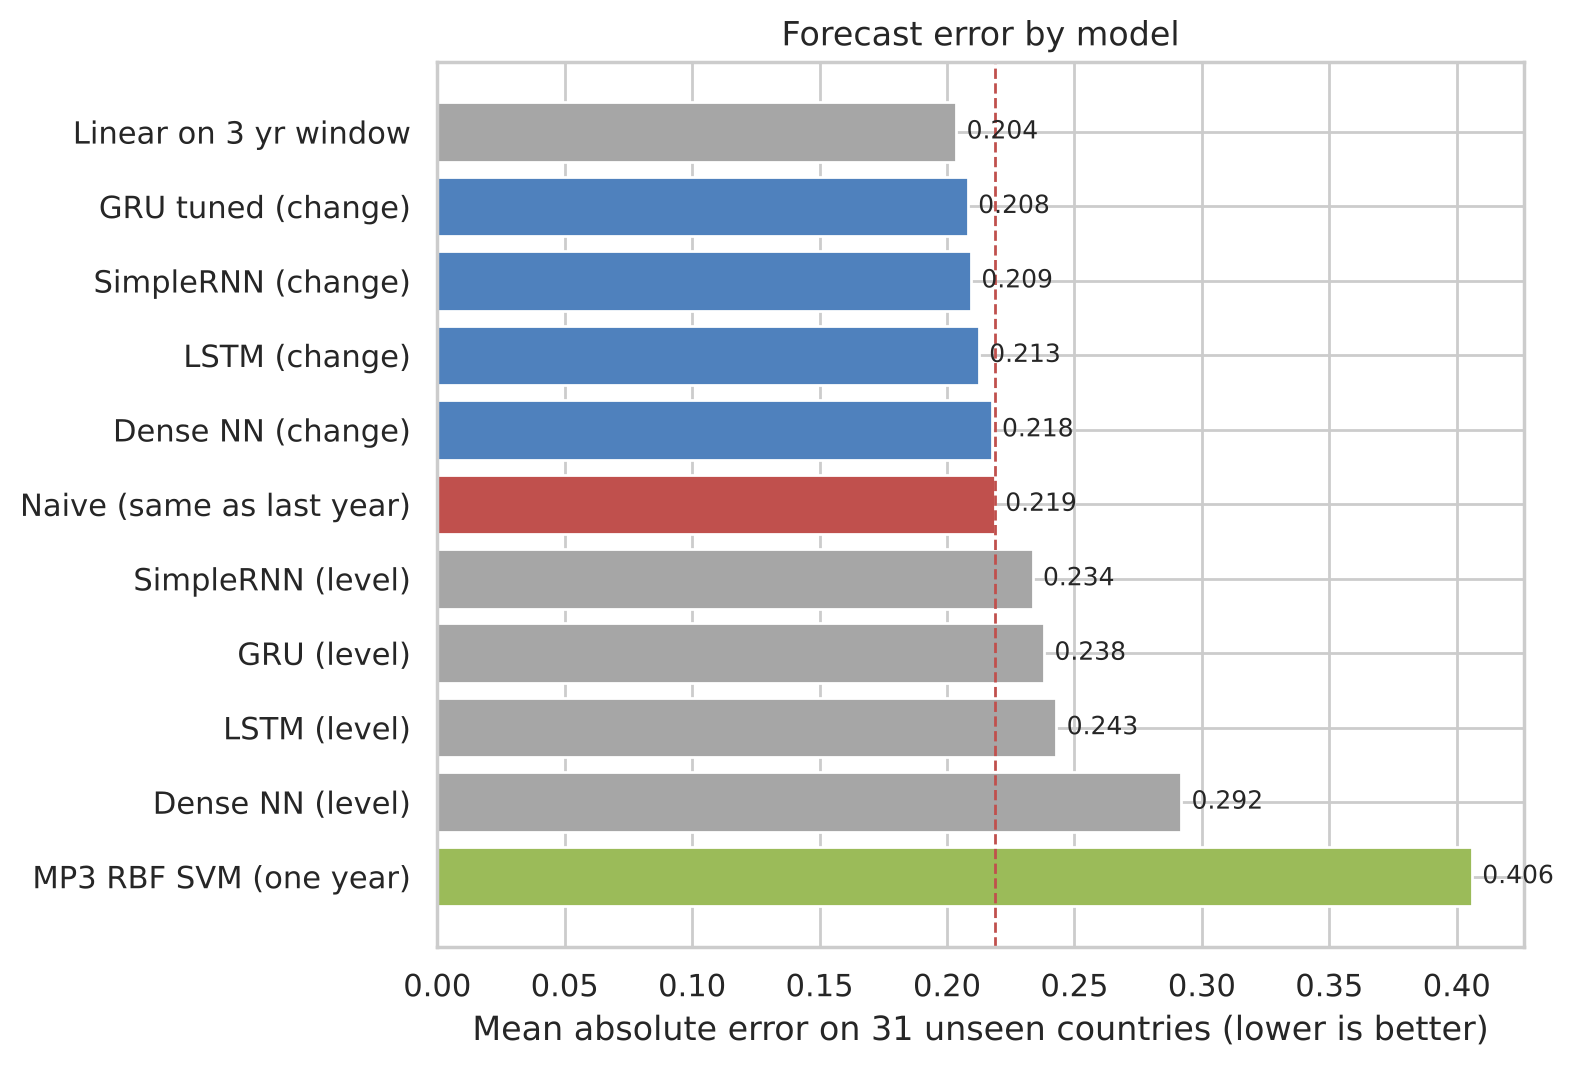

In [17]:
order = table.index[::-1]
colors = ["#c0504d" if "Naive" in n else "#9bbb59" if "MP3" in n
          else "#4f81bd" if "change" in n else "#a6a6a6" for n in order]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(order, table.loc[order, "MAE"], color=colors)
ax.axvline(results["Naive (same as last year)"]["MAE"], color="#c0504d", ls="--", lw=1)
for i, v in enumerate(table.loc[order, "MAE"]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("Mean absolute error on 31 unseen countries (lower is better)")
ax.set_title("Forecast error by model")
plt.tight_layout(); plt.savefig("fig_mae_bars.png", dpi=160); plt.show()

### 4.2 Does the GRU win hold up on other splits?
31 test countries isn't a lot. In MP3 I learned to rerun the comparison on different country splits before trusting
a small win. Here I redo the whole thing (new test countries, new validation countries, new scaler, retrain) on 5
fresh splits and compare the naive forecast, the linear window model and the GRU, all predicting change.

In [18]:
all_countries = np.array(sorted(set(country_all)))
robust = []
for split in range(5):
    gs = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=100 + split)
    _, te = next(gs.split(all_countries, np.zeros(len(all_countries)), all_countries))
    te_mask = np.isin(country_all, all_countries[te])
    Xtr_r, Xte_r = X_seq[~te_mask], X_seq[te_mask]
    ytr_r, yte_r = y_all[~te_mask], y_all[te_mask]
    ltr_r, lte_r = last_score[~te_mask], last_score[te_mask]
    ctr_r = country_all[~te_mask]

    row = {"split": split + 1, "Naive": mean_absolute_error(yte_r, lte_r)}
    lr = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr_r.reshape(len(Xtr_r), -1), ytr_r - ltr_r)
    row["Linear window"] = mean_absolute_error(yte_r, lr.predict(Xte_r.reshape(len(Xte_r), -1)) + lte_r)

    sc = StandardScaler().fit(Xtr_r.reshape(-1, n_cols))
    S = lambda a: sc.transform(a.reshape(-1, n_cols)).reshape(a.shape)
    tc = np.array(sorted(set(ctr_r)))
    vc = np.random.RandomState(split).choice(tc, int(0.15 * len(tc)), replace=False)
    v_mask = np.isin(ctr_r, vc)
    ps = []
    for s in (1, 2, 3):
        keras.utils.set_random_seed(s)
        m = make_gru(int(best.units), best.dropout)()
        m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
        m.fit(S(Xtr_r)[~v_mask], (ytr_r - ltr_r)[~v_mask],
              validation_data=(S(Xtr_r)[v_mask], (ytr_r - ltr_r)[v_mask]),
              epochs=300, batch_size=32, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=25, restore_best_weights=True)])
        ps.append(m.predict(S(Xte_r), verbose=0).ravel() + lte_r)
    row["GRU"] = mean_absolute_error(yte_r, np.mean(ps, axis=0))
    robust.append(row)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()})

robust = pd.DataFrame(robust).set_index("split")
print("\nAverage MAE across 5 splits:")
print(robust.mean().round(3).to_string())
print("\nSplits where GRU beat naive:", (robust["GRU"] < robust["Naive"]).sum(), "of 5")
print("Splits where GRU beat linear:", (robust["GRU"] < robust["Linear window"]).sum(), "of 5")
robust.round(4).to_csv("robustness.csv")

{'split': 1, 'Naive': 0.248, 'Linear window': 0.252, 'GRU': 0.248}


{'split': 2, 'Naive': 0.259, 'Linear window': 0.259, 'GRU': 0.275}


{'split': 3, 'Naive': 0.278, 'Linear window': 0.265, 'GRU': 0.269}


{'split': 4, 'Naive': 0.253, 'Linear window': 0.242, 'GRU': 0.239}


{'split': 5, 'Naive': 0.276, 'Linear window': 0.272, 'GRU': 0.272}

Average MAE across 5 splits:
Naive            0.263
Linear window    0.258
GRU              0.261

Splits where GRU beat naive: 3 of 5
Splits where GRU beat linear: 2 of 5


This is the honest answer. Across different splits, the GRU, the linear window model and the naive forecast are all
within about a hundredth of a point of each other, and which one "wins" changes from split to split. The small GRU
edge on the main split was mostly luck of which countries ended up in the test set.

### 4.3 What about the big swings?
The whole reason I thought an RNN could help was to catch big changes that the naive forecast misses. So I pulled
out the test cases where the score actually moved by more than half a point in one year and compared the models on
just those.

In [19]:
gru_pred = predictions["GRU tuned (change)"]
naive_pred = predictions["Naive (same as last year)"]
actual_change = y_test - last_test
big = np.abs(actual_change) > 0.5

print(f"Big swings (|change| > 0.5): {big.sum()} of {len(y_test)} test windows")
print(f"  Naive MAE on big swings: {mean_absolute_error(y_test[big], naive_pred[big]):.3f}")
print(f"  GRU MAE on big swings:   {mean_absolute_error(y_test[big], gru_pred[big]):.3f}")
print(f"  Naive MAE on normal years: {mean_absolute_error(y_test[~big], naive_pred[~big]):.3f}")
print(f"  GRU MAE on normal years:   {mean_absolute_error(y_test[~big], gru_pred[~big]):.3f}")

pred_change = gru_pred - last_test
print(f"\nAverage size of the real change on big swings:   {np.abs(actual_change[big]).mean():.3f}")
print(f"Average size of the GRU's predicted change there:  {np.abs(pred_change[big]).mean():.3f}")
print(f"Did the GRU at least guess the right direction? {np.mean(np.sign(pred_change[big]) == np.sign(actual_change[big])):.0%}")

Big swings (|change| > 0.5): 33 of 347 test windows
  Naive MAE on big swings: 0.766
  GRU MAE on big swings:   0.687
  Naive MAE on normal years: 0.161
  GRU MAE on normal years:   0.158

Average size of the real change on big swings:   0.766
Average size of the GRU's predicted change there:  0.095
Did the GRU at least guess the right direction? 82%


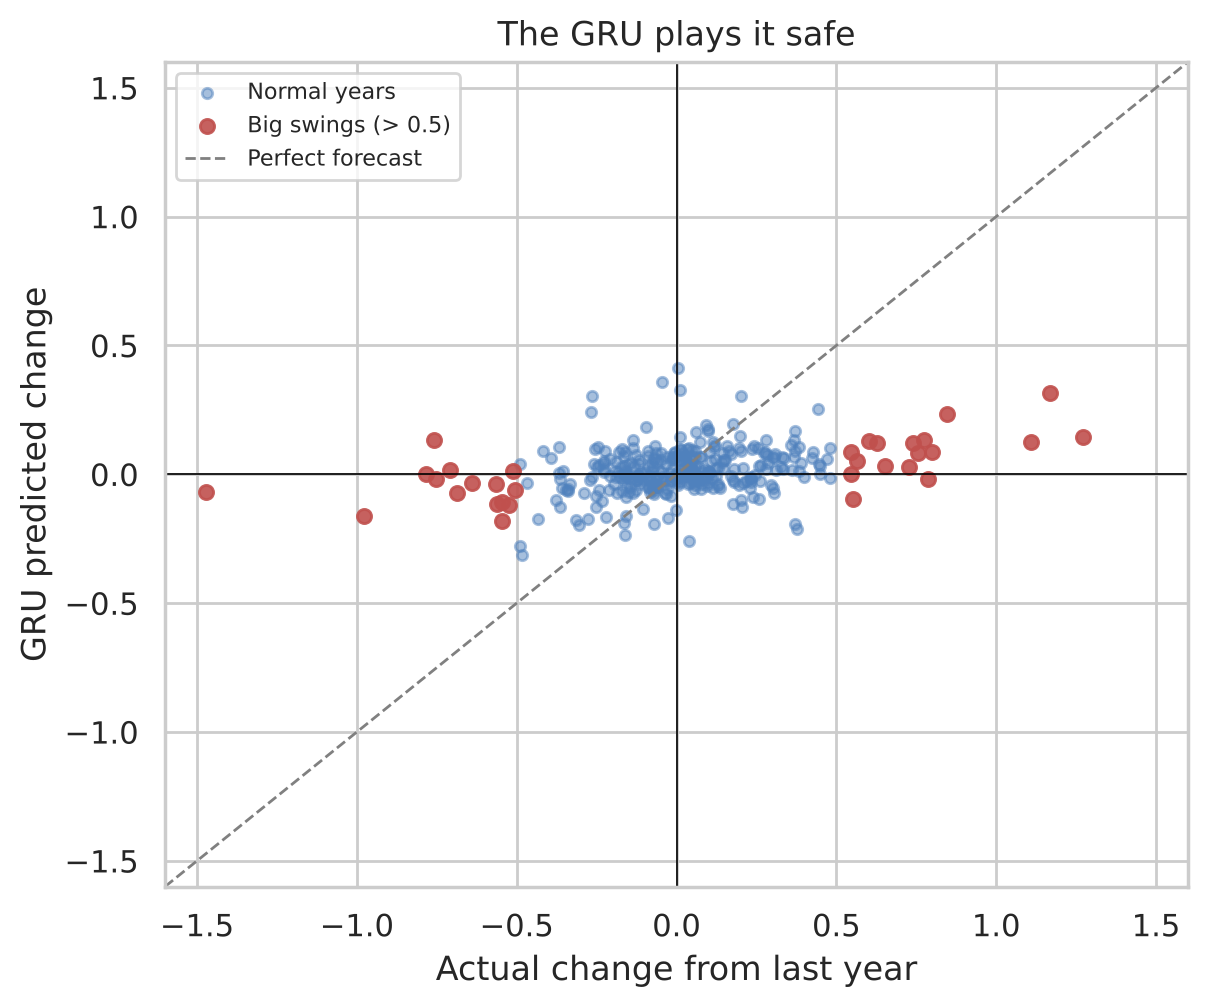

In [20]:
fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.scatter(actual_change[~big], pred_change[~big], s=14, alpha=0.5, color="#4f81bd", label="Normal years")
ax.scatter(actual_change[big], pred_change[big], s=26, alpha=0.9, color="#c0504d", label="Big swings (> 0.5)")
lim = 1.6
ax.plot([-lim, lim], [-lim, lim], color="gray", ls="--", lw=1, label="Perfect forecast")
ax.axhline(0, color="black", lw=0.6); ax.axvline(0, color="black", lw=0.6)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("Actual change from last year"); ax.set_ylabel("GRU predicted change")
ax.set_title("The GRU plays it safe")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig("fig_change_scatter.png", dpi=160); plt.show()

# Save the points so I can rebuild this chart in my slides
pd.DataFrame({"actual_change": actual_change, "predicted_change": pred_change, "big": big}).round(4)   .to_csv("change_points.csv", index=False)

This part was more interesting than I expected. On the 33 big swings, the GRU guessed the right direction 82% of the
time, and it did shave the error down from 0.77 (naive) to 0.69. So it is picking up something real from the trends.

But look at the size. The real changes averaged about 0.77 points, and the GRU only predicted about 0.10. In the
scatter plot the red dots are spread out left and right, while the predictions sit in a flat band near zero. The model
leans the right way but plays it safe. That's actually the smart move for keeping average error low when most years
barely move, but it means it would never warn you about a big drop.

### 4.4 Which countries were hardest?

In [21]:
err = pd.DataFrame({"country": c_test, "year": year_all[is_test], "actual": y_test,
                    "last_year": last_test, "gru": gru_pred})
err["abs_error"] = (err["actual"] - err["gru"]).abs()
worst = err.sort_values("abs_error", ascending=False).head(8)
display(worst.round(2))

by_country = err.groupby("country")["abs_error"].mean().sort_values(ascending=False)
print("Test countries with the highest average error:")
print(by_country.head(5).round(3).to_string())

,country,year,actual,last_year,gru,abs_error
1,Bahrain,2013,6.69,5.03,5.23,1.46
249,South Africa,2013,3.66,5.13,5.06,1.40
126,Guinea,2017,4.87,3.60,3.75,1.12
150,Kenya,2014,4.90,3.80,3.92,0.99
295,Tanzania,2016,2.90,3.66,3.80,0.89
250,South Africa,2014,4.83,3.66,3.98,0.85
288,Tanzania,2009,3.41,4.38,4.22,0.82
17,Bolivia,2009,6.09,5.30,5.28,0.81


Test countries with the highest average error:
country
Botswana        0.459
Guinea          0.383
Bahrain         0.366
South Africa    0.347
Thailand        0.322


A few of these worst misses look like one year blips. South Africa dropped about 1.5 points in 2013 and then bounced
most of the way back in 2014. A swing like that, gone a year later, is probably partly survey noise and not a real
change in how people feel. No model built on income and corruption trends could predict that, and honestly it
shouldn't try.

### 4.5 Summary of findings
* **Hypothesis part 1 is supported.** Every model that sees the last three years beats my MP3 SVM by a wide margin
  (about 0.21 vs 0.41 MAE). Most of that comes from simply knowing last year's score.
* **Hypothesis part 2 is not supported.** The RNNs don't reliably beat "same as last year." Predicting the score
  directly made them worse. Predicting the change got them level with the naive forecast, but across 5 splits the
  difference is basically noise.
* **Deep learning didn't beat linear regression here either.** A plain linear model on the same 3 year window does
  just as well as the GRU.
* **Big swings are still the weak spot.** The GRU usually guesses the right direction (82%) and does a bit better than
  naive on them, but it only predicts about a tenth of the real change, so it still misses most of a sudden drop.

## Step 5. Act

**What this means for the problem.** If someone wanted a forecast of next year's life satisfaction for a country, my
honest recommendation would be to start with last year's score and treat any model as a small adjustment on top of
it. A recurrent neural network doesn't add much over that with this data, and it's harder to explain than a linear
model that does the same job.

**Why the RNN didn't shine here.** RNNs and LSTMs do well when there's a lot of sequential data with real patterns
over time. I had about 1,000 training windows, each only three steps long, and the target barely moves most years.
That's not much for a network to learn from. The things that cause big swings (wars, economic collapses, the pandemic)
aren't in my six inputs at all, so no model built on them could see those coming. And a few big swings look like
survey noise that reverses the next year, which nothing can predict.

**Connecting back to the bigger picture.** This lines up with something from the Uber forecasting case study we
watched. Uber uses classical methods, machine learning and deep learning side by side and picks based on the problem
and the amount of data. They also stress that extreme events are the hardest thing to forecast because there are so
few examples, which is exactly where my GRU struggled.

**What I'd do next.**
1. Add outside data that could actually signal a shock, like inflation, conflict events or unemployment.
2. Try longer windows (5+ years) for countries that have them, to give the RNN more to work with.
3. Predict a range instead of a single number (for example with quantile loss), so a forecast can say "probably
   around 5.5, but could drop to 4.8."
4. Use rolling origin testing (train on years up to 2018, test on 2019, and so on) to check how the model holds up
   over time and not just across countries.

**Limitations.** The test set is small (31 countries), the 3 year window choice wasn't tuned, and survey scores have
their own sampling noise of roughly 0.1 points, which puts a floor on how accurate any model can be.